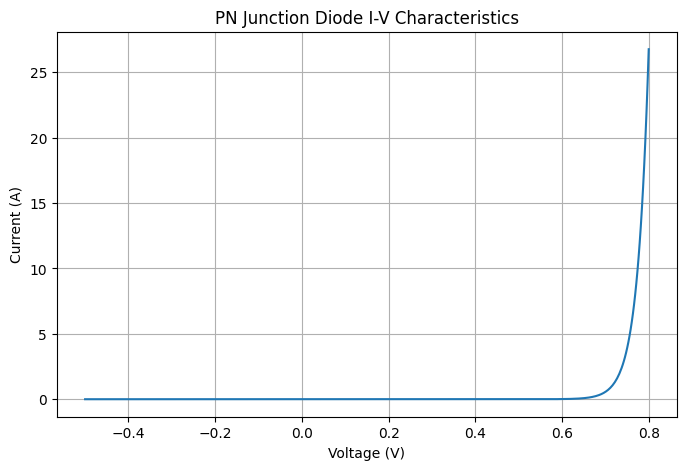

In [2]:

# PROJECT 1: PN JUNCTION DIODE SIMULATOR

import numpy as np
import matplotlib.pyplot as plt

# Constants
Is = 1e-12
n = 1.0
T = 300
k = 1.38e-23
q = 1.6e-19

# Thermal voltage
Vt = k * T / q

# Voltage range
V = np.linspace(-0.5, 0.8, 500)

# Diode current equation
I = Is * (np.exp(V / (n * Vt)) - 1)

# Plot graph
plt.figure(figsize=(8, 5))
plt.plot(V, I)

plt.xlabel("Voltage (V)")
plt.ylabel("Current (A)")
plt.title("PN Junction Diode I-V Characteristics")

plt.grid(True)
plt.show()


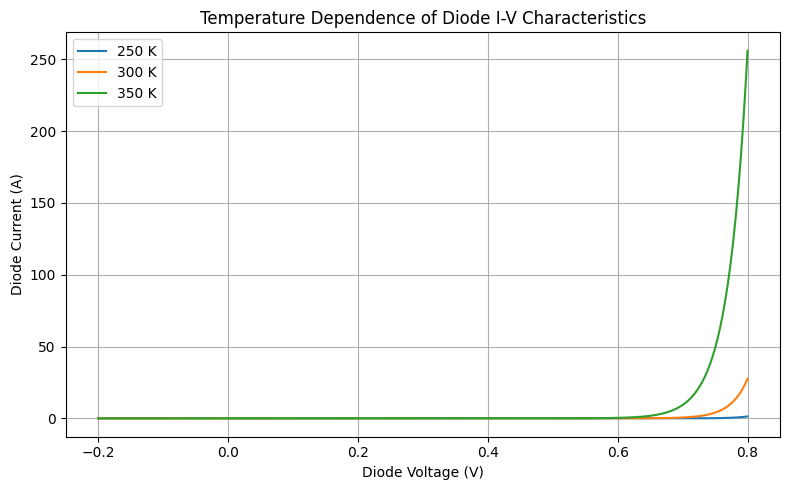

In [8]:

# Temperature Analysis

import numpy as np
import matplotlib.pyplot as plt

k = 1.380649e-23
q = 1.602176634e-19

Is_300 = 1e-12
n = 1.0
T_ref = 300

# Voltage range
V = np.linspace(-0.2, 0.8, 500)

# Temperature values
temperatures = [250, 300, 350]

plt.figure(figsize=(8, 5))

for T in temperatures:

    Vt = k * T / q

    # Approximate temperature-dependent saturation current
    Is_T = Is_300 * (T / T_ref)**3 * np.exp(
        -1.12 / (8.617333262e-5) *
        (1/T - 1/T_ref)
    )

    I = Is_T * (np.exp(V / (n * Vt)) - 1)

    plt.plot(V, I, label=f"{T} K")

plt.xlabel("Diode Voltage (V)")
plt.ylabel("Diode Current (A)")
plt.title("Temperature Dependence of Diode I-V Characteristics")

plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig("Graph_2_Temperature_Analysis.png", dpi=300)
plt.show()


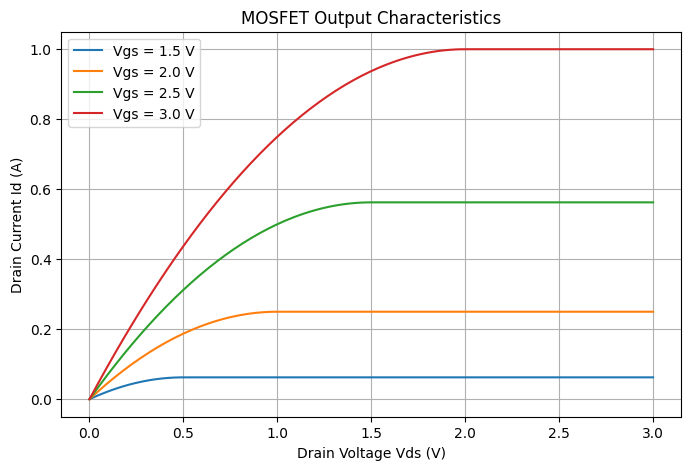

In [3]:

# PROJECT 2: MOSFET SIMULATOR

import numpy as np
import matplotlib.pyplot as plt

# MOSFET parameters
Vth = 1.0
k = 0.5

# Drain voltage
Vds = np.linspace(0, 3, 200)

# Gate voltages
Vgs_values = [1.5, 2.0, 2.5, 3.0]

plt.figure(figsize=(8, 5))

for Vgs in Vgs_values:

    Id = []

    for Vds_value in Vds:

        if Vgs <= Vth:
            current = 0

        elif Vds_value < Vgs - Vth:
            current = k * (
                (Vgs - Vth) * Vds_value
                - (Vds_value**2) / 2
            )

        else:
            current = (
                k / 2
                * (Vgs - Vth)**2
            )

        Id.append(current)

    plt.plot(Vds, Id, label=f"Vgs = {Vgs} V")

plt.xlabel("Drain Voltage Vds (V)")
plt.ylabel("Drain Current Id (A)")
plt.title("MOSFET Output Characteristics")

plt.legend()
plt.grid(True)
plt.show()


In [4]:

# PROJECT 3: SEMICONDUCTOR DATASET

import pandas as pd
import numpy as np

np.random.seed(42)

# Generate data
data = pd.DataFrame({

    "Threshold_Voltage":
        np.random.normal(1.0, 0.05, 1000),

    "Leakage_Current":
        np.random.normal(1e-9, 0.2e-9, 1000),

    "Temperature":
        np.random.normal(300, 5, 1000),

    "Drain_Current":
        np.random.normal(0.01, 0.001, 1000)

})

# Display data
print(data.head())

# Save dataset
data.to_csv("semiconductor_data.csv", index=False)


   Threshold_Voltage  Leakage_Current  Temperature  Drain_Current
0           1.024836     1.279871e-09   296.624109       0.008092
1           0.993087     1.184927e-09   299.277407       0.009140
2           1.032384     1.011926e-09   296.037900       0.009586
3           1.076151     8.706126e-10   298.460192       0.011888
4           0.988292     1.139645e-09   290.531927       0.010557


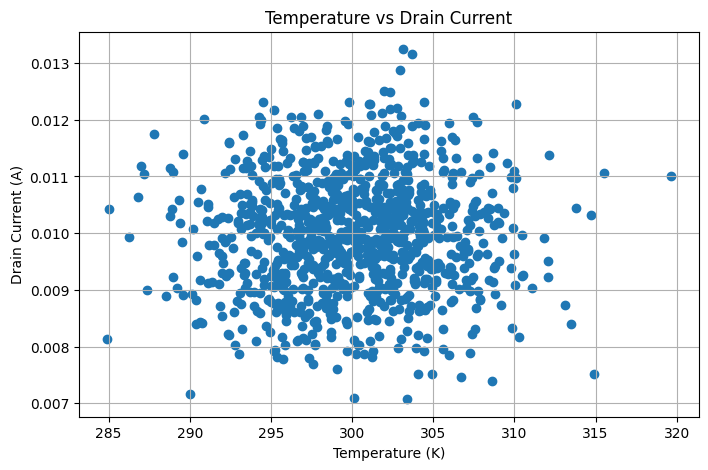

In [5]:

# DATA ANALYSIS

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.scatter(
    data["Temperature"],
    data["Drain_Current"]
)

plt.xlabel("Temperature (K)")
plt.ylabel("Drain Current (A)")

plt.title("Temperature vs Drain Current")

plt.grid(True)

plt.show()


In [6]:

# PROJECT 4: AI ANOMALY DETECTION

from sklearn.ensemble import IsolationForest

# Train AI model
model = IsolationForest(
    contamination=0.05,
    random_state=42
)

# Train using dataset
model.fit(data)

# Predict anomalies
data["AI_Result"] = model.predict(data)

# Show results
print(data.head())

# Count abnormal devices
print(
    "Abnormal devices:",
    (data["AI_Result"] == -1).sum()
)


   Threshold_Voltage  Leakage_Current  Temperature  Drain_Current  AI_Result
0           1.024836     1.279871e-09   296.624109       0.008092          1
1           0.993087     1.184927e-09   299.277407       0.009140          1
2           1.032384     1.011926e-09   296.037900       0.009586          1
3           1.076151     8.706126e-10   298.460192       0.011888          1
4           0.988292     1.139645e-09   290.531927       0.010557          1
Abnormal devices: 50


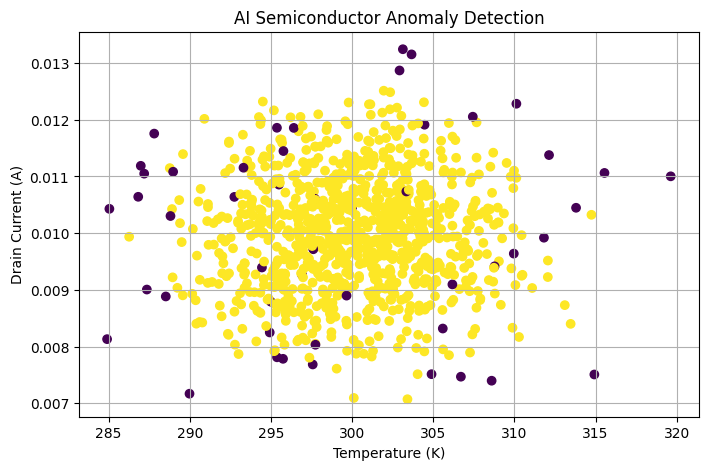

In [7]:

# AI VISUALIZATION

plt.figure(figsize=(8, 5))

plt.scatter(
    data["Temperature"],
    data["Drain_Current"],
    c=data["AI_Result"]
)

plt.xlabel("Temperature (K)")
plt.ylabel("Drain Current (A)")

plt.title("AI Semiconductor Anomaly Detection")

plt.grid(True)

plt.show()
